## MLPI Textbook — Chapter 2 companion notebook

# Data from Machines: Sensors, Preprocessing and Pipelines

---

A maintenance team wants to detect four conditions of the rotating machines on its shop floor:
**normal**, **bearing fault**, **misalignment** and **imbalance**. Every machine has an
accelerometer on its bearing housing, a tachometer on its shaft and a temperature probe, and an
edge device that records one second of vibration a few times per shift.

Before any classifier from Chapter 3 can be trained, that stream of raw signals has to become a
**table**: one row per recording, one column per number, clean enough for scikit-learn to accept.
This chapter is about everything that happens before `fit()` — and about the mistakes made there
that no model can undo.

### What you will be able to do afterwards

1. Turn a raw vibration waveform into condition indicators (RMS, kurtosis, order amplitudes, band
   energy), and explain the sampling rate's role.
2. Diagnose missing data, decide between dropping, imputing and flag-and-fill, and recognise when
   data is *not* missing at random.
3. Choose a scaler, and handle outliers from sensor glitches.
4. Encode categorical fields correctly, including categories never seen in training.
5. Assemble everything into a `ColumnTransformer` + `Pipeline` that is fitted on training data only
   and can be saved and deployed as one object.
6. Split data so the test score predicts performance **on a new machine**, not on a machine the
   model has already seen.

| § | topic |
|---|---|
| 1 | from vibration to numbers |
| 2 | the fleet log |
| 3 | missing data |
| 4 | outliers and feature scaling |
| 5 | categorical fields |
| 6 | pipelines |
| 7 | which features matter? |
| 8 | the decisive experiment: split by machine |
| 9 | shipping the pipeline |

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

# plot style shared by every chapter of the book
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "font.size": 10, "legend.frameon": False,
})
BLUE, ORANGE, AQUA, YELLOW, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781"
CLASS_COLORS = [BLUE, ORANGE, AQUA]

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)


def savefig(name):
    """Save the current figure for the chapter text (figures/<name>.png)."""
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")

python       3.13.18
numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1


---
## 1. From vibration to numbers

### 1.1 What each fault looks like

The simulator below follows standard vibration-analysis physics. A shaft turning at $f$ Hz
produces vibration at $1\times f$; **imbalance** raises that component. **Misalignment** raises the
$2\times f$ harmonic. A **bearing outer-race defect** produces an impact each time a rolling element
passes it — at the *ball-pass frequency* $\text{BPFO}\approx3.58\,f$ for this bearing — and every
impact rings the housing's structural resonance (1.2–2.2 kHz), which decays within a few
milliseconds. On top: electrical noise, a DC offset in the sensor, and a mounting gain that
differs from machine to machine.

In [2]:
FS = 5000          # Hz, accelerometer sample rate
DURATION = 1.0     # s per recording
STATES = ["normal", "bearing fault", "misalignment", "imbalance"]
TYPES = {"CNC": (25.0, 60.0), "press": (10.0, 20.0), "lathe": (15.0, 40.0)}   # running-speed ranges, Hz


def make_fleet(n_per_state=6, seed=2):
    """24 machines; each one stays in ONE condition for the whole logging campaign."""
    rng = np.random.default_rng(seed)
    rows = []
    mid = 0
    types = list(TYPES)
    for s, state in enumerate(STATES):
        for k in range(n_per_state):
            mtype = types[(k + s) % 3]
            lo, hi = TYPES[mtype]
            rows.append(dict(machine_id=f"M{mid:02d}", machine_type=mtype, state=state,
                             speed_hz=rng.uniform(lo, hi),
                             mount_gain=rng.lognormal(0, 0.25),      # how stiffly the sensor is mounted
                             noise_floor=rng.uniform(0.03, 0.08),     # g, electrical + process noise
                             bias_g=rng.normal(0, 0.03),              # accelerometer DC offset
                             resonance_hz=rng.uniform(1200, 2200),    # structural resonance excited by impacts
                             severity=rng.uniform(0.5, 1.0)))
            mid += 1
    return pd.DataFrame(rows)


def simulate_recording(m, rng):
    """One second of housing acceleration (g) for machine row m."""
    t = np.arange(int(FS * DURATION)) / FS
    f = m.speed_hz * rng.normal(1.0, 0.01)             # speed wanders a little between recordings
    a1, a2, imp = 0.20, 0.05, 0.0
    if m.state == "imbalance":     a1 += 0.45 * m.severity
    if m.state == "misalignment":  a2 += 0.30 * m.severity; a1 += 0.08 * m.severity
    if m.state == "bearing fault": imp = 0.9 * m.severity
    x = (a1 * np.sin(2 * np.pi * f * t + rng.uniform(0, 2 * np.pi))
         + a2 * np.sin(2 * np.pi * 2 * f * t + rng.uniform(0, 2 * np.pi)))
    if imp > 0:                                        # impacts at the outer-race defect frequency
        bpfo = 3.58 * f
        for t0 in np.arange(rng.uniform(0, 1 / bpfo), DURATION, 1 / bpfo):
            k = t >= t0
            tau = t[k] - t0
            x[k] += imp * rng.uniform(0.7, 1.3) * np.exp(-tau * 900) * np.sin(2 * np.pi * m.resonance_hz * tau)
    x = m.mount_gain * x + rng.normal(0, m.noise_floor, t.size) + m.bias_g
    return t, x, f


def extract_features(x, speed_hz):
    """Condition indicators computed on the edge device from one recording."""
    xc = x - x.mean()
    rms = np.sqrt(np.mean(xc ** 2))
    spec = np.abs(np.fft.rfft(xc)) * 2 / x.size                 # single-sided amplitude, 1 Hz bins
    freqs = np.fft.rfftfreq(x.size, 1 / FS)
    amp_at = lambda f0: spec[np.abs(freqs - f0) <= 1.5].max()
    band = (freqs >= 1000) & (freqs <= 2400)
    return dict(mean_g=x.mean(), rms_g=rms, ptp_g=np.ptp(x),
                kurtosis=np.mean(xc ** 4) / rms ** 4, crest=np.max(np.abs(xc)) / rms,
                amp_1x_g=amp_at(speed_hz), amp_2x_g=amp_at(2 * speed_hz),
                hf_band_g=np.sqrt(np.sum(spec[band] ** 2) / 2))


def make_sensor_log(fleet, n_per_machine=35, seed=3):
    """The log as the plant historian stores it: features, metadata, and real-world mess."""
    rng = np.random.default_rng(seed)
    rows = []
    for _, m in fleet.iterrows():
        for _ in range(n_per_machine):
            t, x, f = simulate_recording(m, rng)
            if rng.random() < 0.02:                                   # electrostatic spike on the cable
                i = rng.integers(0, x.size); x[i:i + 3] += rng.choice([-1, 1]) * rng.uniform(4, 8)
            feats = extract_features(x, f)
            temp = (38 + {"CNC": 4, "press": 0, "lathe": 2}[m.machine_type]
                    + (5 * m.severity if m.state == "bearing fault" else 0)
                    + (3 * m.severity if m.state == "misalignment" else 0) + rng.normal(0, 2.5))
            rows.append(dict(machine_id=m.machine_id, machine_type=m.machine_type,
                             shift=rng.choice(["A", "B", "C"]), speed_hz=f, temp_C=temp,
                             **feats, state=m.state))
    log = pd.DataFrame(rows)
    # tachometer dropouts: no speed -> no order-tracked amplitudes. The presses' tach is worst.
    p_drop = np.where(log.machine_type == "press", 0.20, 0.05)
    drop = rng.random(len(log)) < p_drop
    log.loc[drop, ["speed_hz", "amp_1x_g", "amp_2x_g"]] = np.nan
    # temperature probe: random 4 % gaps
    log.loc[rng.random(len(log)) < 0.04, "temp_C"] = np.nan
    return log.sample(frac=1.0, random_state=seed).reset_index(drop=True)


fleet = make_fleet()
fleet.head()

,machine_id,machine_type,state,speed_hz,mount_gain,noise_floor,bias_g,resonance_hz,severity
0,M00,CNC,normal,34.156425,0.877492,0.070711,-0.073244,1800.100526,0.864280
1,M01,press,normal,11.879011,1.213431,0.043748,-0.016615,1762.265663,0.575031
2,M02,lathe,normal,25.815770,0.820340,0.051139,-0.002976,2167.435952,0.841532
3,M03,CNC,normal,38.706869,0.800060,0.047298,0.005641,2091.209410,0.887782
4,M04,press,normal,13.181466,1.216278,0.053545,-0.049153,1307.207308,0.552272


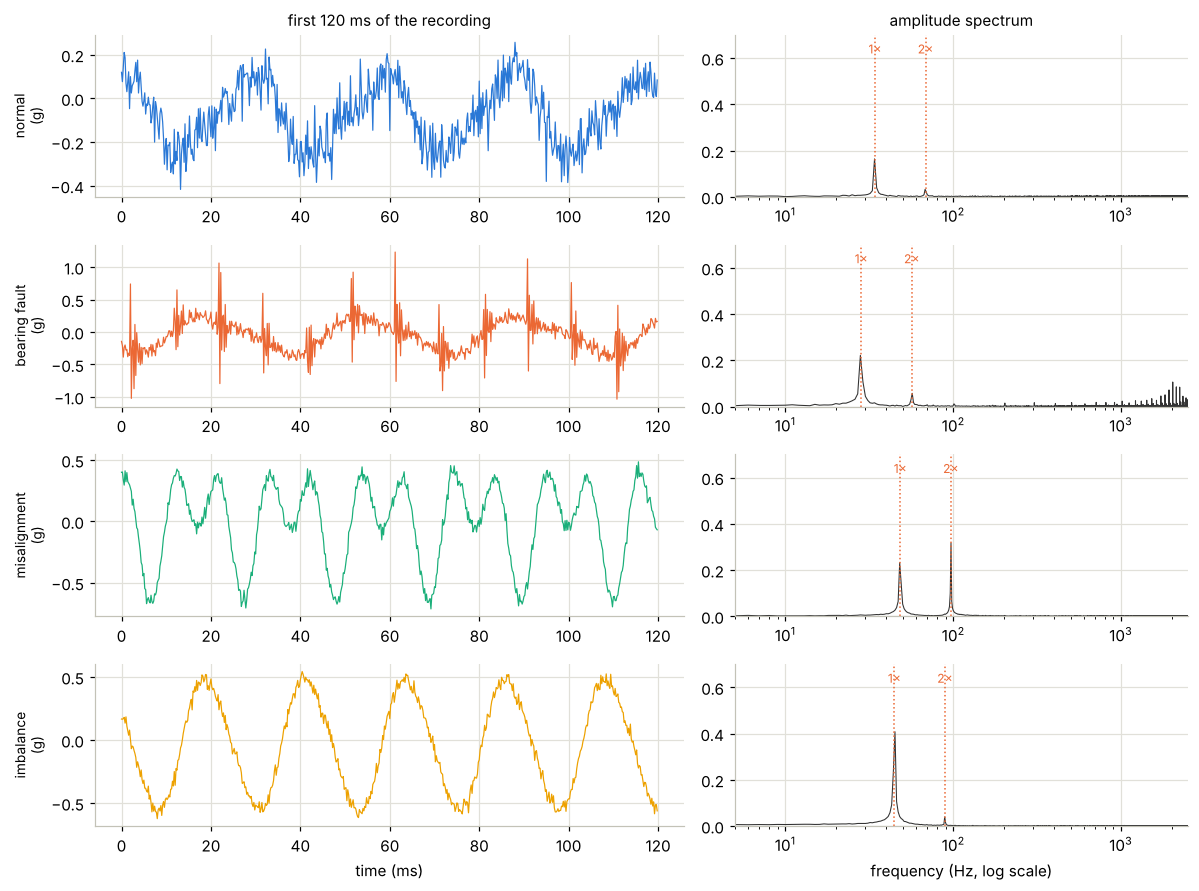

In [3]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(4, 2, figsize=(11, 8.2), gridspec_kw=dict(width_ratios=[1.3, 1]))
for row, state in enumerate(STATES):
    m = fleet[(fleet.state == state) & (fleet.machine_type == "CNC")].iloc[0]
    t, x, f = simulate_recording(m, rng)
    w = t < 0.12
    axes[row, 0].plot(t[w] * 1000, x[w], color=CLASS_COLORS[row % 3] if row < 3 else YELLOW, lw=0.8)
    axes[row, 0].set_ylabel(f"{state}\n(g)", fontsize=9)
    spec = np.abs(np.fft.rfft(x - x.mean())) * 2 / x.size
    freqs = np.fft.rfftfreq(x.size, 1 / FS)
    axes[row, 1].plot(freqs, spec, color="#333", lw=0.7)
    axes[row, 1].set_xscale("log"); axes[row, 1].set_xlim(5, 2500); axes[row, 1].set_ylim(0, 0.7)
    for k, lab in [(1, "1×"), (2, "2×")]:
        axes[row, 1].axvline(k * f, color=ORANGE, ls=":", lw=1)
        axes[row, 1].text(k * f, 0.62, lab, color=ORANGE, fontsize=8, ha="center")
axes[3, 0].set_xlabel("time (ms)"); axes[3, 1].set_xlabel("frequency (Hz, log scale)")
axes[0, 0].set_title("first 120 ms of the recording", fontsize=10)
axes[0, 1].set_title("amplitude spectrum", fontsize=10)
plt.tight_layout(); savefig("ch02_signals"); plt.show()

Imbalance is a bigger sine wave, misalignment adds a wave at twice the frequency, and the bearing
fault adds sharp periodic bursts whose energy sits far up the spectrum, near the resonance.
Normal is the same sine wave as the others, only smaller.

### 1.2 Sampling: the one setting you cannot fix later

The edge device samples at $f_s = 5$ kHz. The **Nyquist–Shannon theorem** says a sampled signal can
only represent frequencies below $f_s/2 = 2.5$ kHz. A component above that is not lost; it is
**aliased** — it reappears at a false, lower frequency. A 1.8 kHz resonance sampled at 2 kHz shows
up at 200 Hz, right in the band where shaft harmonics live:

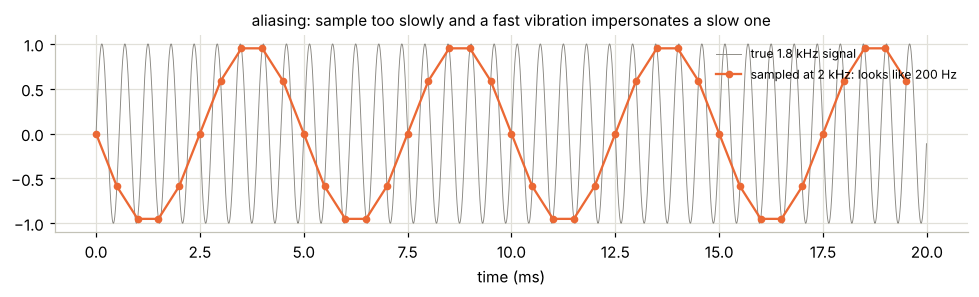

In [4]:
t_fine = np.arange(0, 0.02, 1 / 100_000)
t_slow = np.arange(0, 0.02, 1 / 2000)
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(t_fine * 1000, np.sin(2 * np.pi * 1800 * t_fine), color=MUTED, lw=0.6, label="true 1.8 kHz signal")
ax.plot(t_slow * 1000, np.sin(2 * np.pi * 1800 * t_slow), "o-", color=ORANGE, ms=4, lw=1.5,
        label="sampled at 2 kHz: looks like 200 Hz")
ax.set_xlabel("time (ms)"); ax.legend(loc="upper right", fontsize=8)
ax.set_title("aliasing: sample too slowly and a fast vibration impersonates a slow one", fontsize=10)
plt.tight_layout(); savefig("ch02_aliasing"); plt.show()

No amount of machine learning can undo aliasing, which is why real data-acquisition hardware puts
an analogue **anti-aliasing filter** before the converter. Choose $f_s$ from the highest frequency
you need (here the bearing resonance), with margin.

### 1.3 Condition indicators

A one-second recording is 5000 numbers. Classical models want a handful of meaningful ones. The
edge device computes:

| feature | definition | sensitive to |
|---|---|---|
| `mean_g` | average acceleration | sensor DC offset (should carry no fault information) |
| `rms_g` | $\sqrt{\tfrac1N\sum(x-\bar x)^2}$ | overall vibration energy |
| `ptp_g` | max − min | single large events (and glitches) |
| `kurtosis` | $\tfrac1N\sum(x-\bar x)^4/\text{rms}^4$ | impulsiveness: 1.5 for a pure sine, 3 for Gaussian noise, high for impacts |
| `crest` | peak / RMS | impulsiveness |
| `amp_1x_g`, `amp_2x_g` | spectrum amplitude at $1\times$ and $2\times$ shaft speed | imbalance; misalignment |
| `hf_band_g` | RMS of the 1.0–2.4 kHz band | bearing impacts ringing the resonance |

The order amplitudes need the **shaft speed**, so they come from the tachometer: if the tachometer
drops out, those features cannot be computed.

In [5]:
t, x, f = simulate_recording(fleet[fleet.state == "bearing fault"].iloc[0], rng)
pd.Series(extract_features(x, f)).round(4)

mean_g      -0.0071
rms_g        0.2244
ptp_g        2.2017
kurtosis     3.8898
crest        5.1715
amp_1x_g     0.2179
amp_2x_g     0.0434
hf_band_g    0.1192
dtype: float64

---
## 2. The fleet log

Twenty-four machines (8 CNC mills, 8 presses, 8 lathes) were logged for a campaign of several
weeks, 35 recordings each: 840 rows. Each machine was in **one** condition for the whole campaign —
a misaligned coupling stays misaligned until somebody fixes it — so the six machines of each
condition supply all of its rows. Keep that in mind until §8.

The log also contains the mess every real plant historian contains:

* **tachometer dropouts** — no speed, so no `amp_1x_g` / `amp_2x_g` either; the presses' tachometers
  are the least reliable;
* **gaps in the temperature probe**;
* **electrostatic spikes** on the sensor cable in about 2 % of recordings;
* columns that are metadata rather than measurements: `machine_id`, `machine_type`, `shift`.

In [6]:
log = make_sensor_log(fleet)
print(log.shape)
log.head()

(840, 14)


,machine_id,machine_type,shift,speed_hz,temp_C,mean_g,rms_g,ptp_g,kurtosis,crest,amp_1x_g,amp_2x_g,hf_band_g,state
0,M17,press,B,16.142346,40.365255,0.029702,0.238235,1.165153,2.412215,2.789255,0.224681,0.191185,0.057686,misalignment
1,M11,CNC,A,28.450832,48.986467,0.039356,0.152019,1.497193,4.735374,5.683111,0.097865,0.033122,0.103998,bearing fault
2,M02,lathe,C,25.792389,40.489637,-0.001552,0.131106,0.651726,2.017575,2.559603,0.153845,0.029786,0.038279,normal
3,M13,CNC,B,48.830984,49.943668,-0.009110,0.324769,1.275550,2.237588,2.154549,0.284530,0.284647,0.023821,misalignment
4,M12,lathe,A,34.212671,44.433575,0.000009,0.210175,1.081685,2.374082,2.661161,0.191744,0.142550,0.044940,misalignment


In [7]:
NUM = ["mean_g", "rms_g", "ptp_g", "kurtosis", "crest", "amp_1x_g", "amp_2x_g", "hf_band_g",
       "speed_hz", "temp_C"]
CAT = ["machine_type", "shift"]
log[NUM].describe().round(3).T

,count,mean,std,min,25%,50%,75%,max
mean_g,840.0,-0.009,0.027,-0.076,-0.023,-0.007,0.007,0.044
rms_g,840.0,0.236,0.083,0.125,0.181,0.212,0.295,0.481
ptp_g,840.0,1.361,0.955,0.577,0.849,1.200,1.448,9.017
kurtosis,840.0,6.767,37.785,1.535,1.803,2.244,2.758,540.568
crest,840.0,3.432,3.146,1.674,2.217,2.550,4.211,30.963
amp_1x_g,752.0,0.250,0.122,0.089,0.162,0.216,0.294,0.614
amp_2x_g,752.0,0.083,0.078,0.019,0.036,0.046,0.081,0.347
hf_band_g,840.0,0.059,0.038,0.022,0.034,0.047,0.085,0.195
speed_hz,752.0,28.296,12.350,9.871,17.217,28.410,38.603,55.404
temp_C,812.0,41.374,3.547,31.386,39.036,41.218,43.486,53.116


Already two warnings from `describe()`. `kurtosis` and `ptp_g` have maxima far beyond their 75th
percentiles — the electrostatic spikes. And `count` is below 840 for four columns.

---
## 3. Missing data

scikit-learn estimators refuse `NaN`. Look before deciding what to do:

In [8]:
miss = log[NUM].isna()
by_type = miss.groupby(log.machine_type).mean()[["speed_hz", "amp_1x_g", "temp_C"]]
print("missing fraction per column:")
print(miss.mean().round(3)[miss.mean() > 0].to_string())
print("\nmissing fraction by machine type:")
print(by_type.round(3))

missing fraction per column:
amp_1x_g    0.105
amp_2x_g    0.105
speed_hz    0.105
temp_C      0.033

missing fraction by machine type:
              speed_hz  amp_1x_g  temp_C
machine_type                            
CNC              0.057     0.057   0.039
lathe            0.050     0.050   0.039
press            0.207     0.207   0.021


The temperature gaps look **missing completely at random** (MCAR): the same rate everywhere. The
tachometer gaps do not: presses lose their speed signal four times as often as the other machines.
This is **missing not at random** with respect to machine type, and it changes what each strategy
does to the data.

### 3.1 Three strategies

| strategy | what it does | risk |
|---|---|---|
| **drop** | delete rows (or columns) with any gap | wastes data; if gaps are not random, it skews what is left |
| **impute** | fill gaps with the training column's mean or median | hides the fact that a value was missing |
| **flag and fill** | impute *and* add a 0/1 "was missing" column | one extra column per affected feature |

In [9]:
dropped = log.dropna()
comp = pd.DataFrame({"all rows": log.machine_type.value_counts(normalize=True),
                     "after dropna()": dropped.machine_type.value_counts(normalize=True)}).round(3)
print(f"dropna() keeps {len(dropped)} of {len(log)} rows ({len(dropped)/len(log):.0%})\n")
comp

dropna() keeps 727 of 840 rows (87%)



,all rows,after dropna()
machine_type,,
CNC,0.333,0.348
lathe,0.333,0.351
press,0.333,0.301


Dropping rows quietly turns a fleet that was one-third presses into one where presses are
under-represented — exactly the machines whose sensors are least reliable, so a model trained on
the dropped data has seen the fewest examples of the hardest case.

### 3.2 Mean or median?

When a column contains outliers, the **mean** is dragged toward them; the **median** is not. The
spikes make this concrete:

In [10]:
for col in ["kurtosis", "ptp_g", "temp_C"]:
    print(f"{col:9s} mean {log[col].mean():8.3f}   median {log[col].median():8.3f}")

kurtosis  mean    6.767   median    2.244
ptp_g     mean    1.361   median    1.200
temp_C    mean   41.374   median   41.218


A few spiky recordings pull the mean kurtosis far from where typical recordings sit. Median is the
safer default for sensor features. (Imputing temperature is uncontroversial either way: no spikes.)

### 3.3 Does the choice matter for the model?

We compare the strategies with the same model — logistic regression — and the honest evaluation
scheme introduced in §8 (cross-validation in which each fold holds out whole machines). Every
strategy lives *inside* a pipeline, so the imputer only ever sees training folds.

In [11]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

y_all, groups_all = log["state"], log["machine_id"]
CV_MACHINE = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=0)


def machine_cv(model, X, y=None, groups=None):
    y = y_all if y is None else y
    groups = groups_all if groups is None else groups
    s = cross_val_score(model, X, y, cv=CV_MACHINE, groups=groups)
    return s.mean(), s.std()


def preprocessor(imputer, scaler=None, num=NUM, cat=("machine_type",)):
    steps = [imputer] + ([scaler] if scaler is not None else [StandardScaler()])
    return ColumnTransformer([("num", make_pipeline(*steps), list(num)),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), list(cat))])


rows = []
keep = log.dropna().index
m, s = machine_cv(Pipeline([("pre", preprocessor(SimpleImputer())), ("clf", LogisticRegression(max_iter=3000))]),
                  log.loc[keep], y_all.loc[keep], groups_all.loc[keep])
rows.append(("drop rows with gaps", len(keep), m, s))
for name, imp in [("impute mean", SimpleImputer(strategy="mean")),
                  ("impute median", SimpleImputer(strategy="median")),
                  ("median + missing flags", SimpleImputer(strategy="median", add_indicator=True))]:
    m, s = machine_cv(Pipeline([("pre", preprocessor(imp)), ("clf", LogisticRegression(max_iter=3000))]), log)
    rows.append((name, len(log), m, s))
pd.DataFrame(rows, columns=["strategy", "rows used", "accuracy", "std"]).set_index("strategy").round(3)

,rows used,accuracy,std
strategy,,,
drop rows with gaps,727,0.964,0.071
impute mean,840,0.913,0.082
impute median,840,0.929,0.080
median + missing flags,840,0.912,0.083


Dropping rows *appears* to win — but look at the second column. That score was computed on a
different, easier test set: the 113 recordings it threw away are mostly the presses with a dead
tachometer, and they are still going to arrive in production. A model trained and tested only on
complete rows has **no answer at all** for one press recording in five. Two strategies can only be
compared on the same rows.

Among the strategies that keep every row, the differences (0.91–0.93) are much smaller than the
fold-to-fold standard deviation (about 0.08), so this data does not prefer one of them. The habit
worth forming is not "median always wins" but **decide deliberately, inside the pipeline, evaluate
on the data you will actually face, and check the effect**. Flag-and-fill costs little and keeps
the fact that a value was missing, which matters when missingness is itself a symptom — a
tachometer that drops out *because* the machine vibrates badly.

---
## 4. Outliers and feature scaling

### 4.1 The glitches

An electrostatic discharge on the cable adds a spike of several g for a millisecond. It is not
vibration, but `ptp_g`, `crest` and `kurtosis` take it at face value:

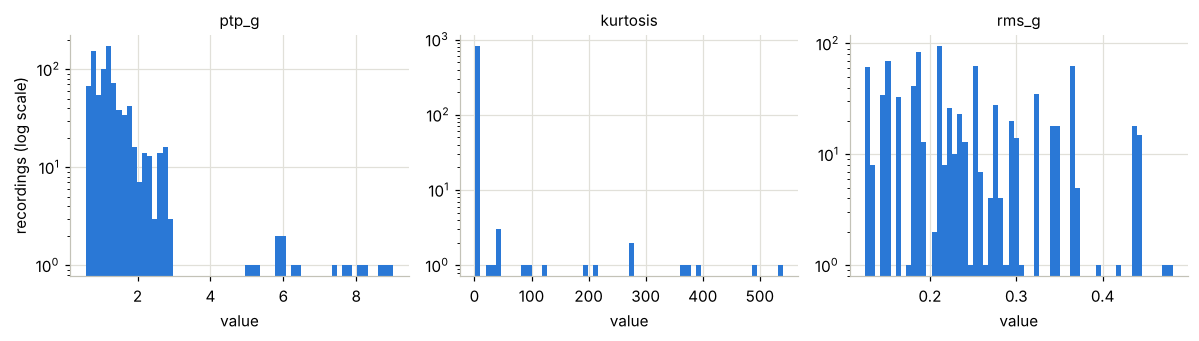

recordings with ptp more than 6x the median: 8 (1.0%)


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a, col in zip(ax, ["ptp_g", "kurtosis", "rms_g"]):
    a.hist(log[col], bins=60, color=BLUE)
    a.set_yscale("log"); a.set_title(col, fontsize=10); a.set_xlabel("value")
ax[0].set_ylabel("recordings (log scale)")
plt.tight_layout(); savefig("ch02_spikes"); plt.show()
spike = log.ptp_g > log.ptp_g.quantile(0.5) * 6
print(f"recordings with ptp more than 6x the median: {spike.sum()} ({spike.mean():.1%})")

`rms_g` is almost unaffected — a 3-sample spike carries little energy over 5000 samples — while
`ptp_g` and `kurtosis` get a long tail. Options: remove the spikes at the signal level (a median
filter on the waveform, best if you control the edge code), clip the feature, or use preprocessing
that is robust to a few extreme values.

### 4.2 Three scalers

| scaler | transform | sensitive to outliers? |
|---|---|---|
| `StandardScaler` | $(x-\mu)/\sigma$ | yes — one spike inflates $\sigma$ |
| `MinMaxScaler` | $(x-\min)/(\max-\min)$ | very — one spike sets the max |
| `RobustScaler` | $(x-\text{median})/\text{IQR}$ | no |

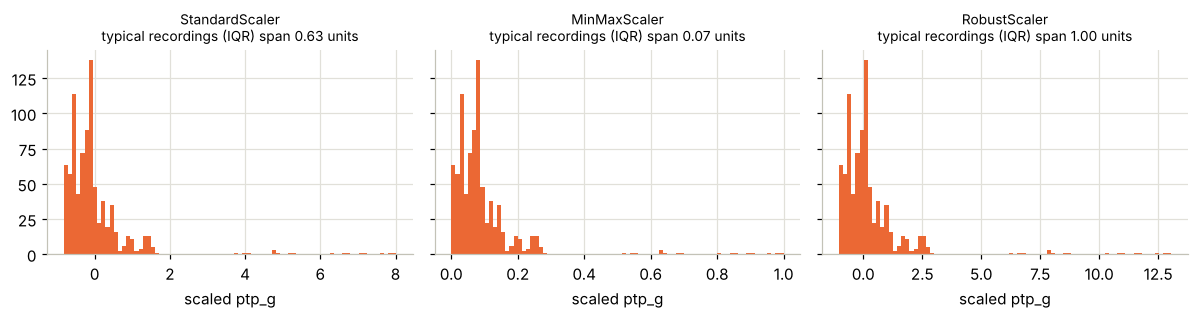

In [13]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler

v = log[["ptp_g"]].to_numpy()
fig, ax = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for a, (name, sc) in zip(ax, [("StandardScaler", StandardScaler()), ("MinMaxScaler", MinMaxScaler()),
                               ("RobustScaler", RobustScaler())]):
    z = sc.fit_transform(v).ravel()
    a.hist(z, bins=80, color=ORANGE)
    q1, q3 = np.percentile(z, [25, 75])
    a.set_title(f"{name}\ntypical recordings (IQR) span {q3 - q1:.2f} units", fontsize=9)
    a.set_xlabel("scaled ptp_g")
plt.tight_layout(); savefig("ch02_scalers"); plt.show()

The shapes are identical — every scaler is a linear map — but the units are not. With
`MinMaxScaler` the handful of spikes define the range, so the middle half of all recordings is
squashed into a band less than a tenth of a unit wide. `RobustScaler` sets its unit from the
interquartile range, so typical recordings keep a spread of one unit no matter how wild the
outliers are. For distance-based models such as k-NN that matters directly:

In [14]:
from sklearn.neighbors import KNeighborsClassifier

rows = []
for name, sc in [("no scaling", "passthrough"), ("StandardScaler", StandardScaler()),
                 ("MinMaxScaler", MinMaxScaler()), ("RobustScaler", RobustScaler())]:
    pre = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), sc), NUM),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), ["machine_type"])])
    for clf_name, clf in [("k-NN (k=7)", KNeighborsClassifier(7)), ("logistic regression", LogisticRegression(max_iter=3000))]:
        m, s = machine_cv(Pipeline([("pre", pre), ("clf", clf)]), log)
        rows.append(dict(scaler=name, model=clf_name, accuracy=m))
pd.DataFrame(rows).pivot(index="scaler", columns="model", values="accuracy").round(3)

model,k-NN (k=7),logistic regression
scaler,,
MinMaxScaler,0.663,0.877
RobustScaler,0.930,0.942
StandardScaler,0.870,0.929
no scaling,0.402,0.846


Without scaling, k-NN's distances are dominated by the features with the largest raw numbers
(temperature in °C, speed in Hz) and it barely beats guessing among four classes. `MinMaxScaler`
helps much less than the other two because the spikes set its range. `RobustScaler`, which ignores
the extremes, does best for both models here. Logistic regression is less sensitive than k-NN, but
not immune: scaling changes how its regularisation penalty treats each weight. Trees, as Chapter 3
shows, need no scaling at all.

---
## 5. Categorical fields

`machine_type` is text. Two tempting shortcuts are both wrong:

* passing the strings straight to a model raises an error;
* mapping them to 0, 1, 2 invents an **order** and a **distance** — "a lathe is twice as far from a
  CNC mill as a press is" — that a linear model or k-NN will take literally.

**One-hot encoding** gives each category its own 0/1 column. Inside a pipeline, use
`OneHotEncoder(handle_unknown="ignore")`: when a category appears at deployment that was never in
the training data, it is encoded as all zeros instead of crashing the line.

In [15]:
enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(log[["machine_type"]])
new = pd.DataFrame({"machine_type": ["CNC", "lathe", "robot"]})      # 'robot' never seen in training
pd.DataFrame(enc.transform(new), columns=enc.get_feature_names_out(), index=new.machine_type)

,machine_type_CNC,machine_type_lathe,machine_type_press
machine_type,,,
CNC,1.0,0.0,0.0
lathe,0.0,1.0,0.0
robot,0.0,0.0,0.0


Not every categorical column deserves a place in the model. `shift` is logged for every recording,
but the fault does not care who is on shift. Section 7 checks whether the model agrees.

---
## 6. Pipelines

Everything so far — imputation, scaling, encoding, the model — has to be **fitted on training data
only** and applied identically to new data. Doing that by hand is where leaks and
train/deploy mismatches creep in. A `ColumnTransformer` routes each group of columns to its own
preprocessing; a `Pipeline` chains that with the model into one estimator with one `fit` and one
`predict`.

```
               ┌─ numeric: SimpleImputer(median, flags) → StandardScaler ─┐
raw table ─────┤                                                          ├─► model
               └─ categorical: OneHotEncoder(handle_unknown="ignore") ────┘
```

In [16]:
FEATURES = NUM + CAT
full_pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
])
pipe = Pipeline([("pre", full_pre), ("clf", LogisticRegression(max_iter=3000))])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of 

In [17]:
pipe.fit(log[FEATURES], y_all)
names = pipe.named_steps["pre"].get_feature_names_out()
print(f"{len(FEATURES)} raw columns -> {len(names)} model inputs:")
print(list(names))

12 raw columns -> 20 model inputs:
['num__mean_g', 'num__rms_g', 'num__ptp_g', 'num__kurtosis', 'num__crest', 'num__amp_1x_g', 'num__amp_2x_g', 'num__hf_band_g', 'num__speed_hz', 'num__temp_C', 'num__missingindicator_amp_1x_g', 'num__missingindicator_amp_2x_g', 'num__missingindicator_speed_hz', 'num__missingindicator_temp_C', 'cat__machine_type_CNC', 'cat__machine_type_lathe', 'cat__machine_type_press', 'cat__shift_A', 'cat__shift_B', 'cat__shift_C']


Three missing-value flags and six one-hot columns were added automatically, and the whole thing is
one object. That object, not a notebook full of loose preprocessing steps, is what gets
evaluated, saved and deployed.

---
## 7. Which features matter?

Two quick ways to ask a fitted pipeline which inputs it uses. **L1-regularised logistic regression**
drives the weights of unhelpful inputs to exactly zero (Chapter 4 explains why). **Permutation
importance** shuffles one raw column at a time in held-out data and measures the accuracy lost.

In [18]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit

tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=1).split(log, groups=groups_all))
Xtr, Xte, ytr, yte = log.iloc[tr][FEATURES], log.iloc[te][FEATURES], y_all.iloc[tr], y_all.iloc[te]

from sklearn.utils.fixes import parse_version
# scikit-learn >= 1.8 selects the L1 penalty with l1_ratio=1; older versions use penalty="l1"
l1_args = (dict(l1_ratio=1.0) if parse_version(sklearn.__version__) >= parse_version("1.8")
           else dict(penalty="l1"))
l1 = Pipeline([("pre", full_pre),
               ("clf", LogisticRegression(solver="saga", C=0.05, max_iter=20000, **l1_args))]).fit(Xtr, ytr)
W = pd.DataFrame(np.abs(l1.named_steps["clf"].coef_).T, index=names, columns=l1.classes_)
print("inputs with non-zero L1 weight for at least one class:")
print(W[(W > 0).any(axis=1)].round(2).to_string())
print("\ndropped by L1:", list(W.index[(W == 0).all(axis=1)]))

inputs with non-zero L1 weight for at least one class:
                bearing fault  imbalance  misalignment  normal
num__mean_g              0.00       0.00          0.00    0.31
num__rms_g               0.00       1.93          0.00    0.82
num__kurtosis            0.00       0.00          0.00    0.13
num__amp_2x_g            0.00       0.00          1.97    0.00
num__hf_band_g           3.41       0.00          0.00    0.00

dropped by L1: ['num__ptp_g', 'num__crest', 'num__amp_1x_g', 'num__speed_hz', 'num__temp_C', 'num__missingindicator_amp_1x_g', 'num__missingindicator_amp_2x_g', 'num__missingindicator_speed_hz', 'num__missingindicator_temp_C', 'cat__machine_type_CNC', 'cat__machine_type_lathe', 'cat__machine_type_press', 'cat__shift_A', 'cat__shift_B', 'cat__shift_C']


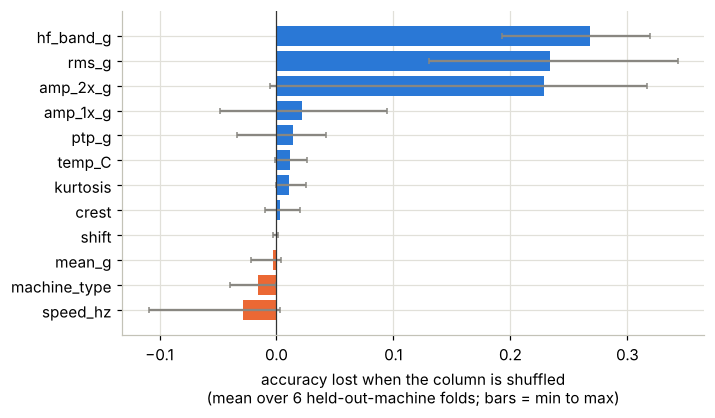

In [19]:
# permutation importance on each held-out-machine fold, then averaged (one split is too noisy)
per_fold = []
for tr_i, te_i in CV_MACHINE.split(log, y_all, groups_all):
    p = Pipeline([("pre", full_pre), ("clf", LogisticRegression(max_iter=3000))])
    p.fit(log.iloc[tr_i][FEATURES], y_all.iloc[tr_i])
    per_fold.append(permutation_importance(p, log.iloc[te_i][FEATURES], y_all.iloc[te_i],
                                           n_repeats=10, random_state=0).importances_mean)
per_fold = pd.DataFrame(per_fold, columns=FEATURES)
imp = per_fold.mean().sort_values()
fig, ax = plt.subplots(figsize=(6.6, 3.9))
ax.barh(imp.index, imp.values, color=[ORANGE if v < 0 else BLUE for v in imp.values],
        xerr=[imp - per_fold.min()[imp.index], per_fold.max()[imp.index] - imp], ecolor=MUTED, capsize=2)
ax.axvline(0, color="#333", lw=0.8)
ax.set_xlabel("accuracy lost when the column is shuffled\n(mean over 6 held-out-machine folds; bars = min to max)")
plt.tight_layout(); savefig("ch02_importance"); plt.show()

The physics comes back out. L1 keeps one main input per fault: the high-frequency band for the
bearing fault, $2\times$ amplitude for misalignment, RMS (which the $1\times$ component dominates)
for imbalance. Permutation importance on held-out machines agrees: `hf_band_g`, `rms_g` and
`amp_2x_g` carry the decisions, and `shift` is worthless.

Two details deserve a second look. L1 kept `mean_g` — the sensor's DC offset — for the *normal*
class. A DC offset has no business predicting a fault; when it shows up, treat it as an alarm, not
a discovery. And `speed_hz` and `machine_type` have **negative** importance on held-out machines
(orange): shuffling them makes predictions on new machines *better*. Both describe *which machine*
a recording came from rather than its condition, and the model leans on them in a way that does not
transfer. Section 8 shows how large that effect is.

---
## 8. The decisive experiment: split by machine

Until §3.3 quietly took care of it, every evaluation in this chapter could have used a random
train/test split. Here is what that would have reported, next to the honest alternative, for three
model families:

* **random split** — 5-fold stratified cross-validation over recordings; recordings from the same
  machine land in both training and test folds;
* **split by machine** — 6-fold cross-validation in which every fold holds out *whole machines*
  (`StratifiedGroupKFold` with `groups=machine_id`).

In [20]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

models = {"logistic regression": LogisticRegression(max_iter=3000),
          "k-NN (k=7)": KNeighborsClassifier(7),
          "random forest": RandomForestClassifier(300, random_state=0, n_jobs=-1)}
cv_random = StratifiedKFold(5, shuffle=True, random_state=0)
rows = []
for feats, label in [(FEATURES, "all features"), ([f for f in FEATURES if f != "mean_g"], "without mean_g")]:
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
         [f for f in NUM if f in feats]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    for name, clf in models.items():
        p = Pipeline([("pre", pre), ("clf", clf)])
        r = cross_val_score(p, log[feats], y_all, cv=cv_random).mean()
        g = cross_val_score(p, log[feats], y_all, cv=CV_MACHINE, groups=groups_all).mean()
        rows.append(dict(features=label, model=name, random_split=r, split_by_machine=g, gap=r - g))
leak = pd.DataFrame(rows).set_index(["features", "model"]).round(3)
leak

random_split  split_by_machine    gap
features       model                                                     
all features   logistic regression         0.981             0.912  0.069
               k-NN (k=7)                  0.955             0.856  0.099
               random forest               0.995             0.917  0.079
without mean_g logistic regression         0.979             0.930  0.049
               k-NN (k=7)                  0.950             0.888  0.062
               random forest               0.995             0.921  0.074

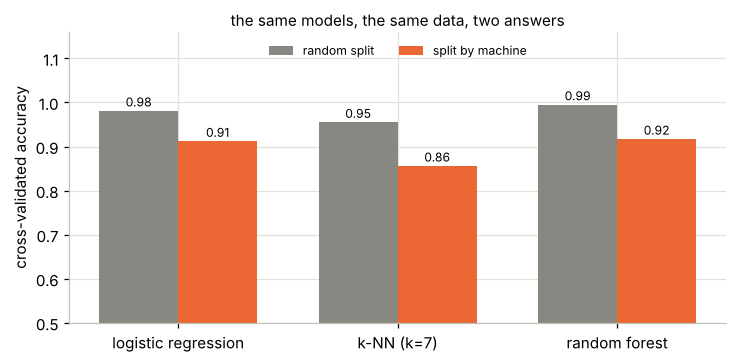

In [21]:
sub = leak.loc["all features"]
xpos = np.arange(len(sub))
fig, ax = plt.subplots(figsize=(6.8, 3.4))
ax.bar(xpos - 0.18, sub.random_split, 0.36, color=MUTED, label="random split")
ax.bar(xpos + 0.18, sub.split_by_machine, 0.36, color=ORANGE, label="split by machine")
for i, (r, g) in enumerate(zip(sub.random_split, sub.split_by_machine)):
    ax.text(i - 0.18, r + 0.01, f"{r:.2f}", ha="center", fontsize=8)
    ax.text(i + 0.18, g + 0.01, f"{g:.2f}", ha="center", fontsize=8)
ax.set_xticks(xpos, sub.index); ax.set_ylim(0.5, 1.16); ax.set_ylabel("cross-validated accuracy")
ax.legend(loc="upper center", ncol=2, fontsize=8)
ax.set_title("the same models, the same data, two answers", fontsize=10, pad=4)
plt.tight_layout(); savefig("ch02_group_split"); plt.show()

**Every model looks better under the random split, and the gap is the size of the leak.** With
recordings from the same machine on both sides, a model can partly recognise *the machine* —
its mounting gain, its noise floor, its sensor offset, its running speed — and every machine has
only one condition, so recognising the machine is enough to "diagnose" it. On a machine it has
never seen, that shortcut is worthless.

Removing `mean_g`, the most obvious fingerprint, narrows the gap — a lot for k-NN, barely for the
random forest — but does not close it, because the fingerprint is spread over many features. Feature surgery is not the fix.
The fix is the split: **the unit you will deploy to — a new machine, a new robot, a new batch, a new
day — must be the unit you hold out.** The number to report to the maintenance manager is the
right-hand bar.

---
## 9. Shipping the pipeline

Because preprocessing and model are one object, deploying them is one file. The edge device or a
plant server loads it and calls `predict` on a raw row — missing values, text categories and all.

In [22]:
import joblib, tempfile

final = Pipeline([("pre", full_pre), ("clf", LogisticRegression(max_iter=3000))]).fit(log[FEATURES], y_all)
path = os.path.join(tempfile.gettempdir(), "fault_pipeline.joblib")
joblib.dump(final, path)
loaded = joblib.load(path)

new_rows = pd.DataFrame([
    dict(machine_type="lathe", shift="B", speed_hz=np.nan, temp_C=41.0, mean_g=0.01, rms_g=0.33,
         ptp_g=1.3, kurtosis=1.6, crest=1.6, amp_1x_g=np.nan, amp_2x_g=np.nan, hf_band_g=0.04),
    dict(machine_type="robot", shift="A", speed_hz=22.0, temp_C=44.5, mean_g=-0.02, rms_g=0.21,
         ptp_g=1.9, kurtosis=4.9, crest=4.4, amp_1x_g=0.17, amp_2x_g=0.05, hf_band_g=0.12),
])
out = pd.DataFrame(loaded.predict_proba(new_rows[FEATURES]), columns=loaded.classes_).round(3)
out.insert(0, "prediction", loaded.predict(new_rows[FEATURES]))
out

,prediction,bearing fault,imbalance,misalignment,normal
0,imbalance,0.0,0.845,0.154,0.0
1,bearing fault,1.0,0.000,0.000,0.0


The first row has no tachometer reading; the second comes from a machine type the model has never
seen. Both are handled without special code. What the pipeline cannot tell you is how much to
trust the second prediction — a new kind of machine is exactly the shift Chapter 7 and Chapter 16
warn about.

---
## Summary

* Sampling rate and sensor placement decide what information exists; no model recovers aliased or
  unrecorded content.
* Condition indicators turn waveforms into a table; build them from the physics of the fault.
* **Missing data**: look at *where* it is missing before choosing to drop, impute or flag. Median
  is the robust default for sensor features.
* **Outliers** from glitches distort `ptp`, kurtosis and min–max scaling; robust statistics or
  signal-level filtering handle them.
* **Categorical fields**: one-hot encode with `handle_unknown="ignore"`; never invent an order.
* **Pipelines** make "fit on training data only" automatic and give one deployable object.
* **Split by the unit you deploy to.** Random splits over recordings from the same machines measure
  memory, not diagnosis.

## Exercises

1. Raise the press tachometer dropout rate to 50 % and repeat §3.3. Which strategy degrades most?
2. Add a median filter (`scipy.signal.medfilt`, kernel 5) to the waveform before feature extraction.
   What happens to the `ptp_g` and `kurtosis` tails, and to the bearing-fault features?
3. Encode `machine_type` as 0/1/2 instead of one-hot and compare k-NN accuracy (split by machine).
4. Lower the sampling rate to 2 kHz in the simulator. Which feature breaks, and what does the
   bearing-fault spectrum look like?
5. Repeat §8 holding out whole **machine types** (all lathes in one fold). Is that a fairer test for
   a plant that is about to buy its first grinder?